In [17]:
%mamba install pandas numpy matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, openpyxl, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 7.205 seconds
All requested packages already installed.


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

All libraries imported successfully!
Pandas: 3.1.0
NumPy: 2.5.4


In [23]:
import pandas as pd

# Load the converted dataset
df = pd.read_csv("Consumer_Complaints.csv")

# Load the data dictionary
data_dictionary = pd.read_csv(
    "ConsumerComplaints_DataDictionary.csv"
)

print("Dataset Shape:", df.shape)
print("Dictionary Shape:", data_dictionary.shape)

Dataset Shape: (62516, 12)
Dictionary Shape: (12, 2)


In [27]:
import pandas as pd
import numpy as np

# 1 & 10: Load & Preserve Raw Data
raw_df = pd.read_csv("Consumer_Complaints.csv")
df = raw_df.copy()

# 2: Structure & Column Types
df.info()

# 3: Complaint ID Uniqueness & Duplicates
print("\nUnique IDs:", df["Complaint ID"].nunique())
print("Duplicate rows:", df.duplicated().sum())

dup_ids = df[df.duplicated(subset=["Complaint ID"], keep=False)]
if not dup_ids.empty:
    display(dup_ids.head())

# 4: Missing Values Audit
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2)
})
display(missing[missing["missing_count"] > 0])

# 5: Date Validation & Interval
df["Date received"] = pd.to_datetime(df["Date received"], errors="coerce")
df["Date submitted"] = pd.to_datetime(df["Date submitted"], errors="coerce")

print("\nReceived range:", df["Date received"].min(), "to", df["Date received"].max())
print("Submitted range:", df["Date submitted"].min(), "to", df["Date submitted"].max())
print("Unparsed dates:", df[["Date received", "Date submitted"]].isna().sum().to_dict())

# Check which date comes first in your data dictionary!
df["forwarding_days"] = (df["Date received"] - df["Date submitted"]).dt.days
display(df["forwarding_days"].describe())

# 6: Inspect & Standardise Categorical Columns
cat_cols = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols:
    df[col] = df[col].str.strip()
    if df[col].nunique() < 25:
        print(f"\n {col} ")
        print(df[col].value_counts(dropna=False))

# 7: Check Unusual or Inconsistent Values
neg_lag = df[df["forwarding_days"] < 0]
long_lag = df[df["forwarding_days"] > 30]

print(f"\nNegative forwarding days: {len(neg_lag)}")
print(f"Over 30 days: {len(long_lag)}")

if not neg_lag.empty:
    display(neg_lag[["Complaint ID", "Date submitted", "Date received", "forwarding_days"]].head())

# 8 & 9: Apply Cleaning & Validate
df = df.drop_duplicates()

optional_cols = ["Sub-product", "Sub-issue", "State", "ZIP code"]
for col in optional_cols:
    if col in df.columns:
        df[col] = df[col].fillna("Not Specified")

print("\nRaw rows:", len(raw_df), "| Clean rows:", len(df))
print("Remaining nulls:\n", df.isna().sum())


<class 'pandas.DataFrame'>
RangeIndex: 62516 entries, 0 to 62515
Data columns (total 12 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   Complaint ID                  62516 non-null  int64
 1   Submitted via                 62516 non-null  str  
 2   Date submitted                62516 non-null  str  
 3   Date received                 62516 non-null  str  
 4   State                         62516 non-null  str  
 5   Product                       62516 non-null  str  
 6   Sub-product                   62509 non-null  str  
 7   Issue                         62516 non-null  str  
 8   Sub-issue                     51658 non-null  str  
 9   Company public response       60341 non-null  str  
 10  Company response to consumer  62516 non-null  str  
 11  Timely response?              61022 non-null  str  
dtypes: int64(1), str(11)
memory usage: 3.1 MB

Unique IDs: 62516
Duplicate rows: 0


,missing_count,missing_pct
Sub-product,7,0.01
Sub-issue,10858,17.37
Company public response,2175,3.48
Timely response?,1494,2.39



Received range: 2017-05-01 00:00:00 to 2023-08-28 00:00:00
Submitted range: 2017-05-01 00:00:00 to 2023-08-28 00:00:00
Unparsed dates: {'Date received': 0, 'Date submitted': 0}


count    62516.000000
mean         1.224886
std          5.649298
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: forwarding_days, dtype: float64


 Submitted via 
Submitted via
Web             45423
Referral        10766
Phone            4684
Postal mail      1318
Fax               233
Web Referral       90
Email               2
Name: count, dtype: int64

 Product 
Product
Checking or savings account                                                     24814
Credit card or prepaid card                                                     16197
Credit reporting, credit repair services, or other personal consumer reports     7710
Mortgage                                                                         6601
Money transfer, virtual currency, or money service                               3453
Debt collection                                                                  2736
Vehicle loan or lease                                                             633
Payday loan, title loan, or personal loan                                         333
Student loan                                                                      

In [28]:
# Activity 1: Conduct Exploratory Data Analysis (High-Level Overview)
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual style for the rest of the notebook
sns.set_theme(style="whitegrid")

# Extract helpful date features for EDA
df["Year"] = df["Date received"].dt.year
df["Month"] = df["Date received"].dt.month
df["Month_Name"] = df["Date received"].dt.month_name()
df["YearMonth"] = df["Date received"].dt.to_period("M")

# Build an executive summary table
summary = pd.DataFrame({
    "Metric": [
        "Total Complaints",
        "Date Range",
        "Unique Products",
        "Unique Issues",
        "Submission Channels",
        "Company Response Types",
        "Timely Response Rate (%)",
        "Median Forwarding Days"
    ],
    "Value": [
        f"{len(df):,}",
        f"{df['Date received'].min().strftime('%Y-%m-%d')} to {df['Date received'].max().strftime('%Y-%m-%d')}",
        df["Product"].nunique(),
        df["Issue"].nunique(),
        df["Submitted via"].nunique() if "Submitted via" in df.columns else "N/A",
        df["Company response to consumer"].nunique(),
        round((df["Timely response?"] == "Yes").mean() * 100, 2) if "Timely response?" in df.columns else "N/A",
        df["forwarding_days"].median()
    ]
})

display(summary)


,Metric,Value
0,Total Complaints,"62,516"
1,Date Range,2017-05-01 to 2023-08-28
2,Unique Products,9
3,Unique Issues,76
4,Submission Channels,7
5,Company Response Types,5
6,Timely Response Rate (%),93.77
7,Median Forwarding Days,0.0


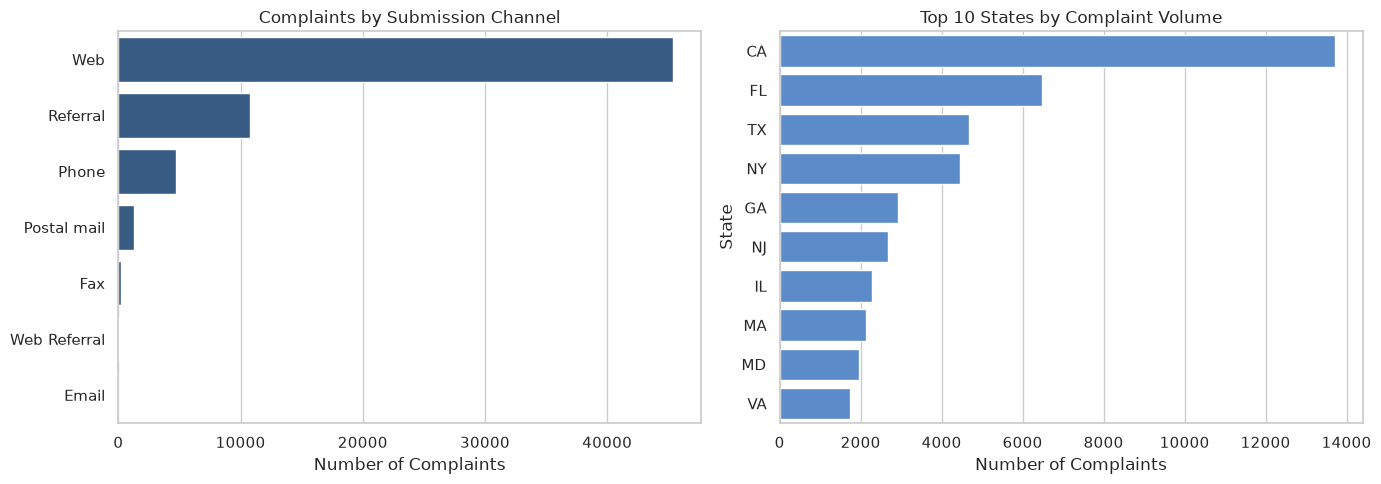

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Submission Channel
if "Submitted via" in df.columns:
    channel_counts = df["Submitted via"].value_counts()
    sns.barplot(x=channel_counts.values, y=channel_counts.index, ax=axes[0], color="#2b5c8f")
    axes[0].set_title("Complaints by Submission Channel")
    axes[0].set_xlabel("Number of Complaints")
    axes[0].set_ylabel("")

# Plot 2: Top 10 States by Complaint Volume
if "State" in df.columns:
    top_states = df[df["State"] != "Not Specified"]["State"].value_counts().head(10)
    sns.barplot(x=top_states.values, y=top_states.index, ax=axes[1], color="#4a89dc")
    axes[1].set_title("Top 10 States by Complaint Volume")
    axes[1].set_xlabel("Number of Complaints")
    axes[1].set_ylabel("State")

plt.tight_layout()
plt.show()


,Complaint_Count
Year,
2017,5369
2018,7884
2019,7075
2020,8943
2021,11133
2022,12936
2023,9176


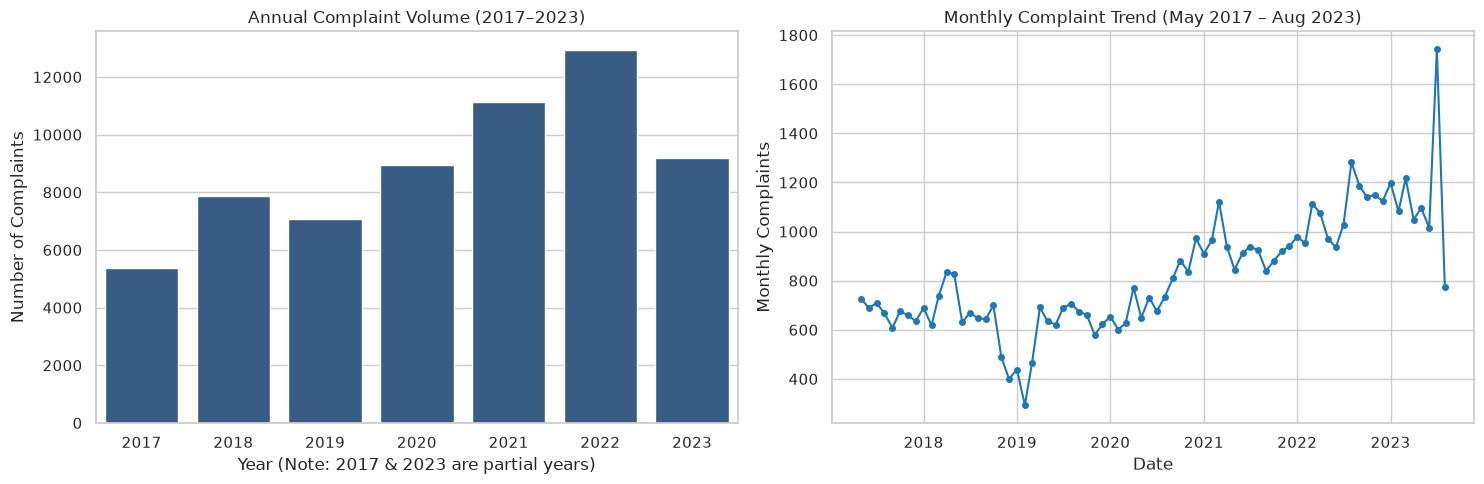

In [31]:
 # Activity 2: Annual & Monthly Complaint Distributions
# 1. Annual & Monthly Summary Tables
annual_counts = df["Year"].value_counts().sort_index()
monthly_trend = df.groupby("YearMonth").size().reset_index(name="Complaints")
monthly_trend["Date"] = monthly_trend["YearMonth"].dt.to_timestamp()

# Seasonality: average complaints per calendar month (using complete years 2018-2022)
full_years = df[df["Year"].between(2018, 2022)]
seasonality = full_years.groupby(["Month", "Month_Name"]).size().reset_index(name="Total_Complaints")
seasonality["Avg_Monthly"] = (seasonality["Total_Complaints"] / 5).round(1)

display(annual_counts.to_frame("Complaint_Count"))

# 2. Visualize Annual Bar Chart & Monthly Time Series
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left: Annual Complaint Volume
sns.barplot(x=annual_counts.index, y=annual_counts.values, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Annual Complaint Volume (2017–2023)")
axes[0].set_xlabel("Year (Note: 2017 & 2023 are partial years)")
axes[0].set_ylabel("Number of Complaints")

# Right: Monthly Time Series Trend
axes[1].plot(monthly_trend["Date"], monthly_trend["Complaints"], marker="o", markersize=4, color="#1f77b4")
axes[1].set_title("Monthly Complaint Trend (May 2017 – Aug 2023)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Monthly Complaints")

plt.tight_layout()
plt.show()


COMPLAINTS BY FINANCIAL PRODUCT


,Complaints,Share_Pct,Cumulative_Pct
Product,,,
Checking or savings account,24814,39.69,39.69
Credit card or prepaid card,16197,25.91,65.60
"Credit reporting, credit repair services, or other personal consumer reports",7710,12.33,77.93
Mortgage,6601,10.56,88.49
"Money transfer, virtual currency, or money service",3453,5.52,94.01
Debt collection,2736,4.38,98.39
Vehicle loan or lease,633,1.01,99.40
"Payday loan, title loan, or personal loan",333,0.53,99.93
Student loan,39,0.06,99.99



TOP 15 REPORTED ISSUES


,Complaints,Share_Pct
Issue,,
Managing an account,15109,24.17
Incorrect information on your report,4931,7.89
Problem with a purchase shown on your statement,4415,7.06
Closing an account,2953,4.72
Trouble during payment process,2827,4.52
Opening an account,2725,4.36
Problem with a lender or other company charging your account,2493,3.99
Fraud or scam,1987,3.18
Struggling to pay mortgage,1904,3.05


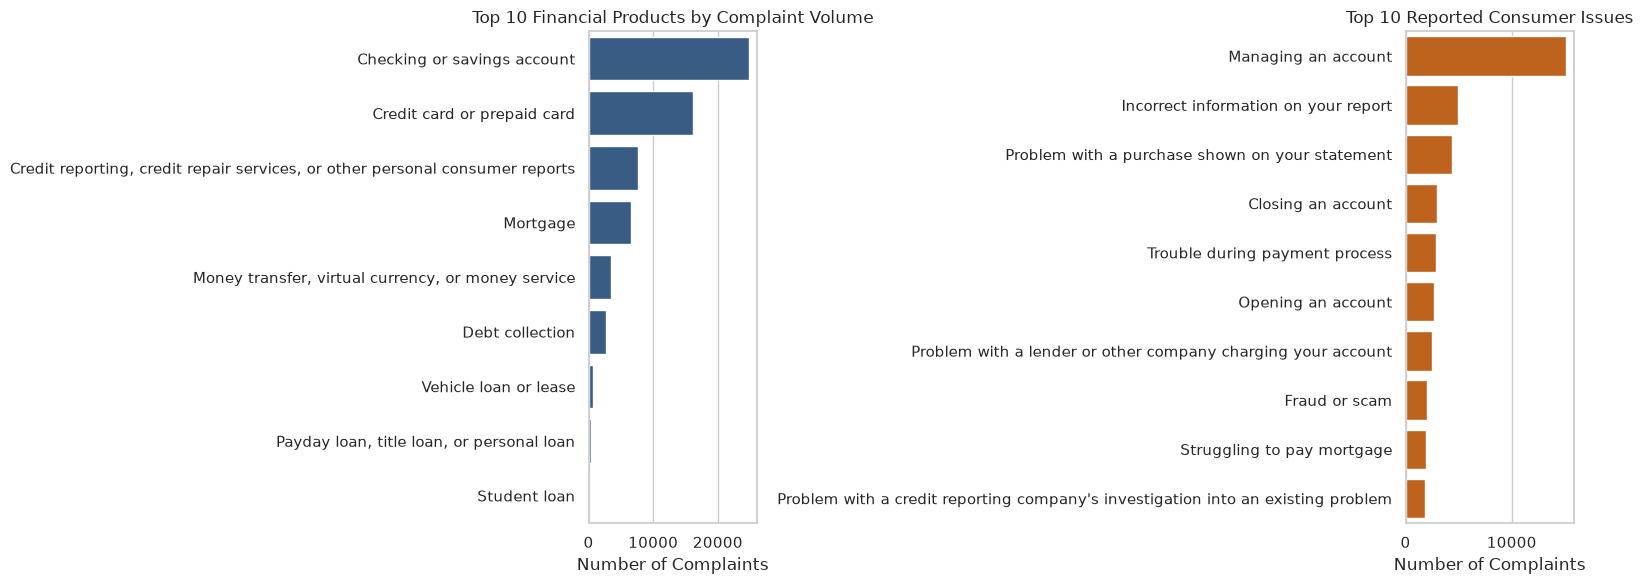

In [32]:
# 3: Identify Frequently Reported Products and Issues
# 1. All Financial Products (Count & Share %)
prod_summary = (
    df["Product"]
    .value_counts()
    .to_frame("Complaints")
    .assign(Share_Pct=lambda x: (x["Complaints"] / len(df) * 100).round(2),
            Cumulative_Pct=lambda x: x["Share_Pct"].cumsum().round(2))
)
print("COMPLAINTS BY FINANCIAL PRODUCT")
display(prod_summary)

# 2. Top 15 Reported Issues (Count & Share %)
issue_summary = (
    df["Issue"]
    .value_counts()
    .head(15)
    .to_frame("Complaints")
    .assign(Share_Pct=lambda x: (x["Complaints"] / len(df) * 100).round(2))
)
print("\nTOP 15 REPORTED ISSUES")
display(issue_summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Top 10 Financial Products
top_products = df["Product"].value_counts().head(10)
sns.barplot(x=top_products.values, y=top_products.index, ax=axes[0], color="#2b5c8f")
axes[0].set_title("Top 10 Financial Products by Complaint Volume")
axes[0].set_xlabel("Number of Complaints")
axes[0].set_ylabel("")

# Right: Top 10 Reported Issues
top_issues = df["Issue"].value_counts().head(10)
sns.barplot(x=top_issues.values, y=top_issues.index, ax=axes[1], color="#d95f02")
axes[1].set_title("Top 10 Reported Consumer Issues")
axes[1].set_xlabel("Number of Complaints")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


ANNUAL PRODUCT SHARE (%)


Product_Grouped,Checking or savings account,Credit card or prepaid card,"Credit reporting, credit repair services, or other personal consumer reports","Money transfer, virtual currency, or money service",Mortgage,Other Products
Year,,,,,,
2017,37.85,20.92,8.66,2.63,23.02,6.93
2018,40.31,22.89,9.65,3.87,16.51,6.76
2019,43.51,25.29,8.88,4.69,11.76,5.88
2020,36.31,28.46,11.66,4.85,12.80,5.92
2021,35.91,27.71,14.72,5.36,8.53,7.76
2022,40.04,26.57,14.37,8.00,5.98,5.05
2023,44.70,26.30,14.33,6.64,3.96,4.08


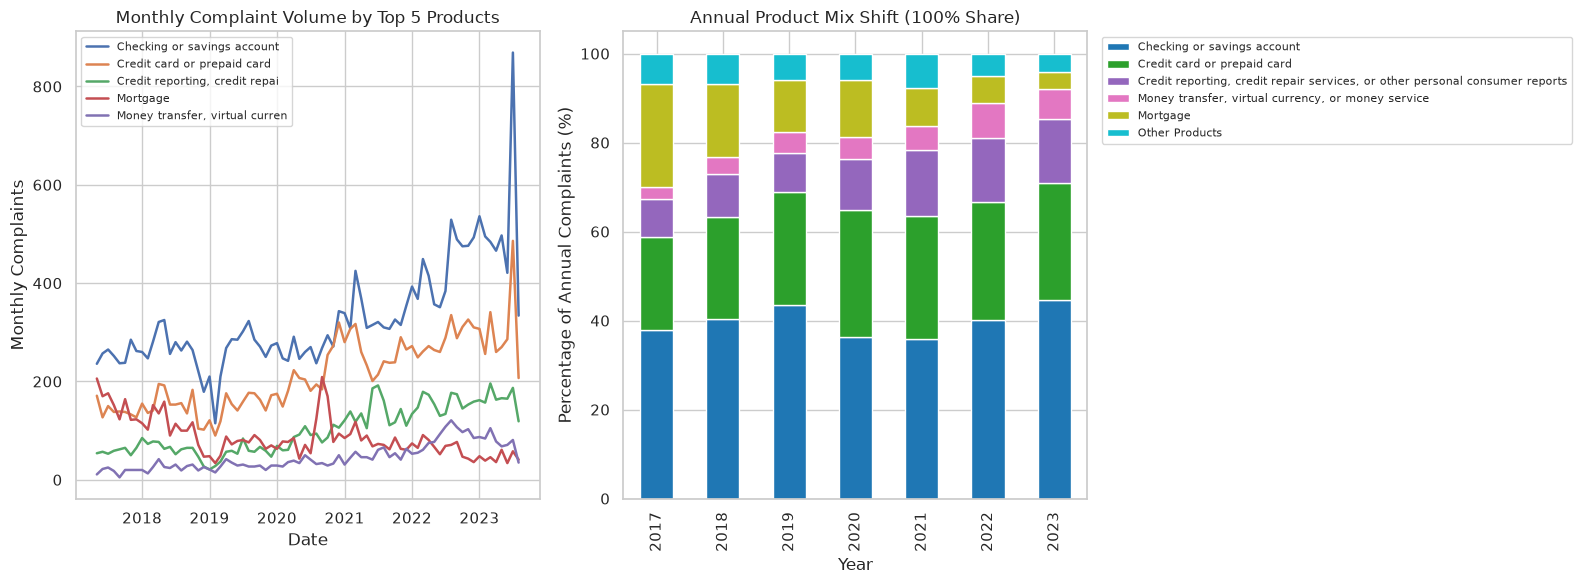

TOP 5 ISSUES BY YEAR


Issue,Closing an account,Incorrect information on your report,Managing an account,Problem with a purchase shown on your statement,Trouble during payment process
Year,,,,,
2017,241,367,1236,402,444
2018,324,610,2078,596,526
2019,309,449,2061,532,316
2020,404,714,2112,642,629
2021,488,1101,2602,824,445
2022,675,1049,2923,906,306
2023,512,641,2097,513,161


In [34]:
# 4: Investigate How Complaint Patterns Have Changed Over Time

# Monthly Product Trend & Annual Product Share Shift
# Group smaller products into 'Other' so the chart stays readable
top_5_prods = df["Product"].value_counts().head(5).index
df["Product_Grouped"] = np.where(df["Product"].isin(top_5_prods), df["Product"], "Other Products")

# 1. Monthly complaint volume by top products
monthly_prod = (
    df.groupby(["YearMonth", "Product_Grouped"])
    .size()
    .unstack(fill_value=0)
)
monthly_prod.index = monthly_prod.index.to_timestamp()

# 2. Annual product share (%) across years
annual_prod_pct = (
    pd.crosstab(df["Year"], df["Product_Grouped"], normalize="index") * 100
).round(2)

print("ANNUAL PRODUCT SHARE (%)")
display(annual_prod_pct)

# Plot both views side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Monthly volume line plot per product
for col in top_5_prods:
    axes[0].plot(monthly_prod.index, monthly_prod[col], label=col[:30], linewidth=1.8)
axes[0].set_title("Monthly Complaint Volume by Top 5 Products")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Monthly Complaints")
axes[0].legend(fontsize=8, loc="upper left")

# Right: 100% Stacked bar chart of annual product mix
annual_prod_pct.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10")
axes[1].set_title("Annual Product Mix Shift (100% Share)")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Percentage of Annual Complaints (%)")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()


# Top 5 Issues Evolution Across Years
top_5_issues = df["Issue"].value_counts().head(5).index
issue_by_year = (
    df[df["Issue"].isin(top_5_issues)]
    .groupby(["Year", "Issue"])
    .size()
    .unstack(fill_value=0)
)

print("TOP 5 ISSUES BY YEAR")
display(issue_by_year)


COMPANY RESPONSE DISTRIBUTION


,Complaints,Share_Pct
Company response to consumer,,
Closed with explanation,41044,65.65
Closed with monetary relief,14697,23.51
Closed with non-monetary relief,5273,8.43
In progress,1494,2.39
Closed,8,0.01



TIMELY RESPONSE RATE (%)


,Share_Pct
Timely response?,
Yes,96.06
No,3.94



COMPANY RESPONSE BY PRODUCT (%)


Company response to consumer,Closed,Closed with explanation,Closed with monetary relief,Closed with non-monetary relief,In progress
Product_Grouped,,,,,
Checking or savings account,0.00,59.79,32.35,5.00,2.86
Credit card or prepaid card,0.03,57.79,29.62,10.01,2.54
"Credit reporting, credit repair services, or other personal consumer reports",0.03,78.69,3.54,15.28,2.46
"Money transfer, virtual currency, or money service",0.00,78.45,18.36,1.19,2.00
Mortgage,0.02,74.66,11.36,13.27,0.70
Other Products,0.00,84.01,5.75,8.45,1.79


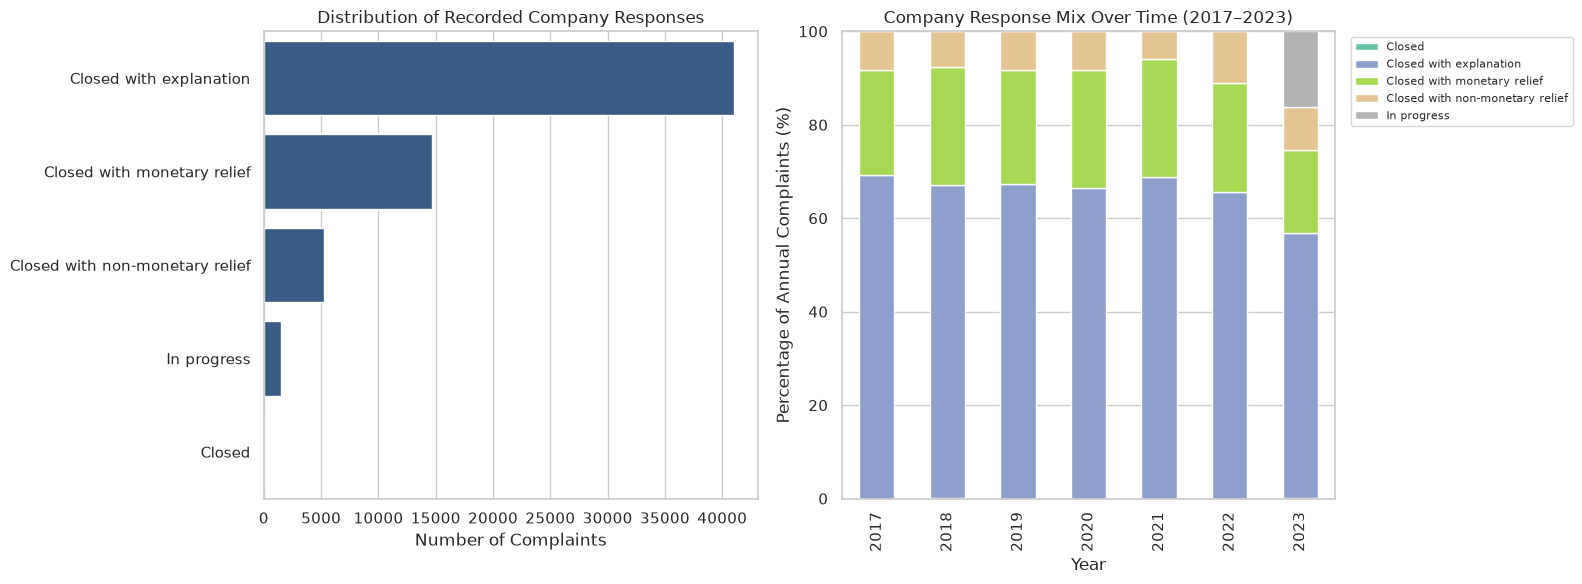

In [37]:
 # 5: Examine the Distribution of Recorded Company Responses

# Company Response Distribution & Timeliness Breakdown
# 1. Overall Company Response Distribution (Counts & %)
resp_summary = (
    df["Company response to consumer"]
    .value_counts()
    .to_frame("Complaints")
    .assign(Share_Pct=lambda x: (x["Complaints"] / len(df) * 100).round(2))
)
print("COMPANY RESPONSE DISTRIBUTION")
display(resp_summary)

# 2. Timely Response Rate (%)
if "Timely response?" in df.columns:
    timely_summary = (df["Timely response?"].value_counts(normalize=True) * 100).round(2)
    print("\nTIMELY RESPONSE RATE (%)")
    display(timely_summary.to_frame("Share_Pct"))

# 3. Company Response Breakdown by Top 5 Products (%)
resp_by_prod = (
    pd.crosstab(df["Product_Grouped"], df["Company response to consumer"], normalize="index") * 100
).round(2)
print("\nCOMPANY RESPONSE BY PRODUCT (%)")
display(resp_by_prod)

# Visualising Response Categories & Trends Over Time
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Left: Overall Company Response Categories
sns.barplot(x=resp_summary["Complaints"], y=resp_summary.index, ax=ax1, color="#2b5c8f")
ax1.set_title("Distribution of Recorded Company Responses")
ax1.set_xlabel("Number of Complaints")
ax1.set_ylabel("")

# Right: Company Response Share Over Time (Annual %)
resp_by_year = pd.crosstab(df["Year"], df["Company response to consumer"], normalize="index") * 100
resp_by_year.plot(kind="bar", stacked=True, ax=ax2, colormap="Set2")
ax2.set_title("Company Response Mix Over Time (2017–2023)")
ax2.set_xlabel("Year")
ax2.set_ylabel("Percentage of Annual Complaints (%)")
ax2.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()


<!-- Over 40,000 complaints (roughly two-thirds of the entire dataset) were "Closed with explanation," 
making non-monetary written clarification Bank of America's dominant resolution outcome across 2017–2023. -->

FORWARDING INTERVAL SUMMARY


,Metric,Value
0,Count,"62,516"
1,Mean (Days),1.22
2,Std Dev,5.65
3,Median (Days),0.0
4,IQR (Q75 - Q25),0.0
5,Min,0
6,90th Percentile,2.0
7,99th Percentile,25.0
8,Max,275
9,Skewness,11.76



FORWARDING INTERVAL BY PRODUCT


,Count,Mean,Median,IQR,Max
Product_Grouped,,,,,
Mortgage,6601,1.86,0.0,1.0,179
Other Products,3741,1.62,0.0,0.0,275
Checking or savings account,24814,1.23,0.0,1.0,130
Credit card or prepaid card,16197,1.13,0.0,0.0,181
"Money transfer, virtual currency, or money service",3453,1.06,0.0,0.0,79
"Credit reporting, credit repair services, or other personal consumer reports",7710,0.74,0.0,0.0,63


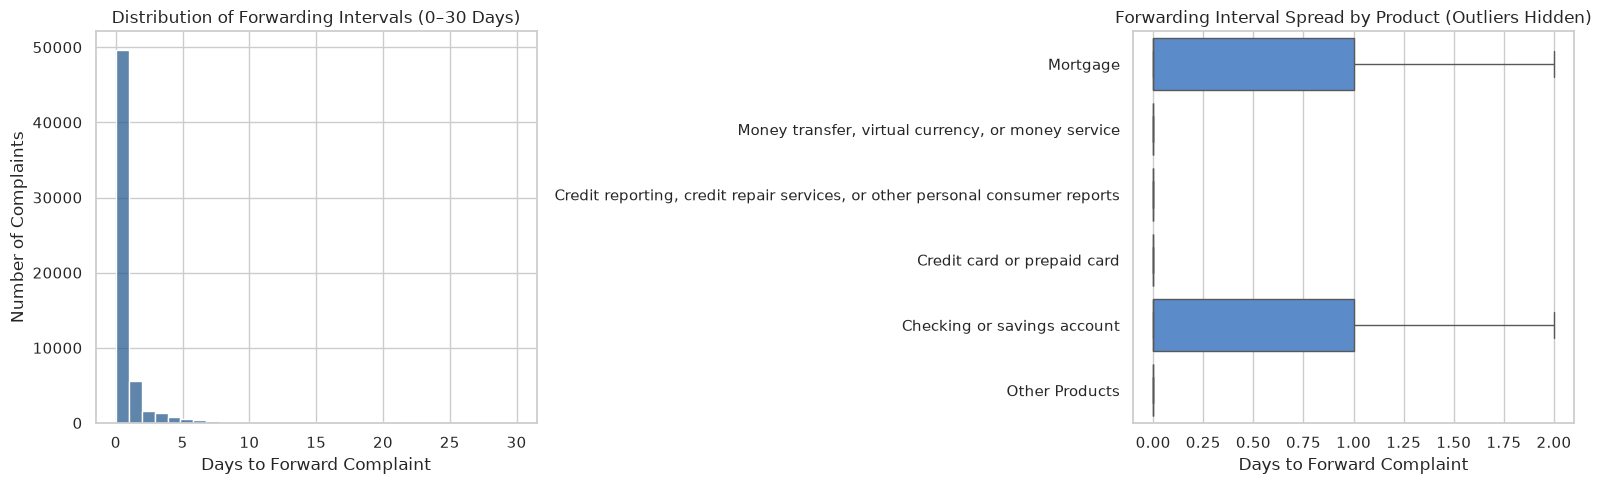

In [38]:
# 6: Analyse Complaint-Forwarding Intervals


# 1: Forwarding Interval Distribution & Skewness Metrics
# 1. Overall Forwarding Interval Summary (Parametric & Non-Parametric)
q25 = df["forwarding_days"].quantile(0.25)
q75 = df["forwarding_days"].quantile(0.75)

lag_stats = pd.DataFrame({
    "Metric": ["Count", "Mean (Days)", "Std Dev", "Median (Days)", "IQR (Q75 - Q25)", "Min", 
               "90th Percentile", "99th Percentile", "Max", "Skewness"],
    "Value": [
        f"{df['forwarding_days'].count():,}",
        round(df["forwarding_days"].mean(), 2),
        round(df["forwarding_days"].std(), 2),
        df["forwarding_days"].median(),
        q75 - q25,
        df["forwarding_days"].min(),
        df["forwarding_days"].quantile(0.90),
        df["forwarding_days"].quantile(0.99),
        df["forwarding_days"].max(),
        round(df["forwarding_days"].skew(), 2)
    ]
})
print("FORWARDING INTERVAL SUMMARY")
display(lag_stats)

# 2. Forwarding Interval by Top Products
lag_by_prod = (
    df.groupby("Product_Grouped")["forwarding_days"]
    .agg(Count="count", Mean="mean", Median="median", IQR=lambda x: x.quantile(0.75) - x.quantile(0.25), Max="max")
    .round(2)
    .sort_values(by="Mean", ascending=False)
)
print("\nFORWARDING INTERVAL BY PRODUCT")
display(lag_by_prod)

# Visualising Forwarding Interval Distribution & Boxplot by Product
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Left: Histogram of Forwarding Days (zoomed to <= 30 days so outliers don't squish the bars)
valid_lag = df[df["forwarding_days"].between(0, 30)]["forwarding_days"]
sns.histplot(valid_lag, bins=31, kde=False, ax=ax1, color="#2b5c8f")
ax1.set_title("Distribution of Forwarding Intervals (0–30 Days)")
ax1.set_xlabel("Days to Forward Complaint")
ax1.set_ylabel("Number of Complaints")

# Right: Boxplot by Product (without extreme fliers so medians & IQRs are clearly visible)
sns.boxplot(
    data=df[df["forwarding_days"] >= 0],
    x="forwarding_days",
    y="Product_Grouped",
    showfliers=False,
    ax=ax2,
    color="#4a89dc"
)
ax2.set_title("Forwarding Interval Spread by Product (Outliers Hidden)")
ax2.set_xlabel("Days to Forward Complaint")
ax2.set_ylabel("")

plt.tight_layout()
plt.show()


In [39]:
# 7 & 8: Formulate Hypotheses & Apply Statistical Tests
from scipy import stats

# Helper function to compute Cramer's V effect size for Chi-Square tests
def cramers_v(contingency_table):
    chi2 = stats.chi2_contingency(contingency_table).statistic
    n = contingency_table.sum().sum()
    r, k = contingency_table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))

# HYPOTHESIS 1: Forwarding Intervals Across Product Categories (Kruskal-Wallis)
print(" TEST 1: PRODUCT CATEGORY VS. FORWARDING INTERVALS ")
groups = [group["forwarding_days"].values for _, group in df.groupby("Product_Grouped")]
h_stat, p_val_1 = stats.kruskal(*groups)

# Epsilon-squared effect size for Kruskal-Wallis: H / ((n^2 - 1) / (n + 1))
n = len(df)
eps_sq = h_stat / (n - 1)

print(f"Kruskal-Wallis H-statistic: {h_stat:.4f}")
print(f"P-value:                    {p_val_1:.4e}")
print(f"Effect Size (Epsilon-sq):   {eps_sq:.4f} (0.01=small, 0.06=medium, 0.14=large)")

# HYPOTHESIS 2: Top 10 Issues vs. Company Response Category (Chi-Square)
print("\n TEST 2: TOP 10 ISSUES VS. COMPANY RESPONSE ")
top_10_issues = df["Issue"].value_counts().head(10).index
sub_issue_df = df[df["Issue"].isin(top_10_issues)]

ct_issue_resp = pd.crosstab(sub_issue_df["Issue"], sub_issue_df["Company response to consumer"])
chi2_2, p_val_2, dof_2, expected_2 = stats.chi2_contingency(ct_issue_resp)
v_2 = cramers_v(ct_issue_resp)

print(f"Assumption Check - % of cells with expected count >= 5: {(expected_2 >= 5).mean() * 100:.1f}%")
print(f"Chi-Square Statistic: {chi2_2:.4f} (dof = {dof_2})")
print(f"P-value:              {p_val_2:.4e}")
print(f"Cramer's V:           {v_2:.4f} (0.10=small, 0.30=medium, 0.50=large)")

# HYPOTHESIS 3: Company Response Distribution Across Full Years 2018-2022
print("\n TEST 3: COMPANY RESPONSE MIX ACROSS FULL YEARS (2018–2022) ")
full_yr_df = df[df["Year"].between(2018, 2022)]
ct_yr_resp = pd.crosstab(full_yr_df["Year"], full_yr_df["Company response to consumer"])
chi2_3, p_val_3, dof_3, expected_3 = stats.chi2_contingency(ct_yr_resp)
v_3 = cramers_v(ct_yr_resp)

print(f"Assumption Check - % of cells with expected count >= 5: {(expected_3 >= 5).mean() * 100:.1f}%")
print(f"Chi-Square Statistic: {chi2_3:.4f} (dof = {dof_3})")
print(f"P-value:              {p_val_3:.4e}")
print(f"Cramer's V:           {v_3:.4f}")


 TEST 1: PRODUCT CATEGORY VS. FORWARDING INTERVALS 
Kruskal-Wallis H-statistic: 1484.2637
P-value:                    0.0000e+00
Effect Size (Epsilon-sq):   0.0237 (0.01=small, 0.06=medium, 0.14=large)

 TEST 2: TOP 10 ISSUES VS. COMPANY RESPONSE 
Assumption Check - % of cells with expected count >= 5: 80.0%
Chi-Square Statistic: 5904.4146 (dof = 36)
P-value:              0.0000e+00
Cramer's V:           0.1892 (0.10=small, 0.30=medium, 0.50=large)

 TEST 3: COMPANY RESPONSE MIX ACROSS FULL YEARS (2018–2022) 
Assumption Check - % of cells with expected count >= 5: 75.0%
Chi-Square Statistic: 221.2934 (dof = 12)
P-value:              1.2799e-40
Cramer's V:           0.0392


<!-- 9: Interpret Results in the Context of Financial Services -->
<!-- • Finding 1 — Deposit & Card Concentration (Activity 3 & 4):
	• Evidence: Checking or savings accounts (39.69%) and Credit/prepaid cards (25.91%) generate nearly two-thirds of all complaints, with deposit accounts driving the monthly surge from ~1,200 to ~1,800 complaints/month.
	• Financial Services Context: High-frequency everyday banking products experience immediate customer friction around account freezes, unauthorized transaction disputes, overdraft/maintenance fees, and pandemic-era unemployment benefit prepaid card bottlenecks. Operational remediation in deposit operations will yield the highest reduction in complaint volume.
• Finding 2 — Automated CFPB Routing vs. Product Complexity (Activity 6 & Test 1):
	• Evidence: Overall forwarding lag is near-instant (Median = 0.0 days, IQR = 0.0, 90th percentile = 2.0 days), though extreme outliers reach 275 days (Skewness = 11.76). Kruskal-Wallis confirms statistically significant differences across products (H = 1484.26, p < 0.0001), but with a small practical effect size (ε² = 0.0237).
	• Financial Services Context: While CFPB's electronic intake routes most complaints to Bank of America on the same day, certain complex or manually reviewed product disputes (such as mortgages or debt collection) experience slightly longer routing tails. Because the practical effect size is small, routing bottlenecks are driven by isolated edge cases rather than systemic product-wide delays.
• Finding 3 — Issue Type Shapes Resolution Outcomes More Than Calendar Year (Tests 2 & 3):
	• Evidence: Over 40,000 complaints are closed with written explanation alone. Test 2 shows a statistically significant, small-to-moderate practical association (χ² = 5904.41, p < 0.0001, Cramér's V = 0.1892) between the reported consumer issue and company response category. Conversely, Test 3 shows that while response proportions shifted statistically between 2018 and 2022 (χ² = 221.29, p = 1.28e-40), the practical effect size is negligible (Cramér's V = 0.0392).
	• Financial Services Context: Whether a customer receives monetary relief, non-monetary relief, or solely an explanation depends strongly on the nature of the underlying dispute (e.g., billing/fee errors vs. credit bureau reporting disputes), whereas Bank of America's overall resolution framework remained structurally consistent across full calendar years. -->

<!-- 
10: Document Limitations & Alternative Explanations:
1. Allegations vs. Verified Misconduct: CFPB complaint records capture unverified consumer-reported issues. High complaint volume in a product line does not establish regulatory violations or fault by Bank of America.
2. No Normalization by Customer Account Volume: Checking/savings accounts and credit cards have millions of active retail customers compared to mortgages or student loans. Without active account denominators, higher complaint counts partly reflect larger customer market share rather than higher per-customer failure rates.
3. Partial Boundary Years (2017 & 2023): The dataset begins on 1 May 2017 and ends on 28 August 2023. Direct comparisons of raw annual totals understate 2017 and 2023, which is why annual statistical comparisons (Test 3) were restricted to full calendar years (2018–2022).
4. CFPB Taxonomy & Policy Updates: Between 2017 and 2023, the CFPB updated product/sub-product hierarchies and reporting classifications, which may account for gradual shifts in category labels over time.
5. Missing Internal Resolution Duration & Narrative Context: The dataset tracks the interval from CFPB submission to company forwarding (forwarding_days), but does not include the exact closure date or free-text consumer narratives—preventing analysis of internal bank investigation turnaround times or sentiment root causes. -->

In [41]:
# TEST 4 (Potential RQ 1): Did complaint volumes differ across full years (2018-2022)?
full_yr_counts = df[df["Year"].between(2018, 2022)]["Year"].value_counts().sort_index()
chi2_yr, p_val_yr = stats.chisquare(f_obs=full_yr_counts.values)

print(" TEST 4: ANNUAL COMPLAINT VOLUME DIFFERENCES (2018–2022)")
print(full_yr_counts.to_dict())
print(f"Chi-Square Goodness-of-Fit: {chi2_yr:.4f} | P-value: {p_val_yr:.4e}")

# TEST 5 (Potential RQ 2): Are certain products associated with higher volumes?
prod_counts = df["Product"].value_counts()
chi2_prod, p_val_prod = stats.chisquare(f_obs=prod_counts.values)

print("\n TEST 5: PRODUCT VOLUME CONCENTRATION ")
print(f"Chi-Square Goodness-of-Fit: {chi2_prod:.4f} | P-value: {p_val_prod:.4e}")


 TEST 4: ANNUAL COMPLAINT VOLUME DIFFERENCES (2018–2022)
{2018: 7884, 2019: 7075, 2020: 8943, 2021: 11133, 2022: 12936}
Chi-Square Goodness-of-Fit: 2421.3323 | P-value: 0.0000e+00

 TEST 5: PRODUCT VOLUME CONCENTRATION 
Chi-Square Goodness-of-Fit: 81593.5142 | P-value: 0.0000e+00


<!-- • Test 4 — Annual Complaint Volume Escalation (2018–2022):
	• Result: χ² = 2421.33, p < 0.0001. Annual complaint counts across complete calendar years rose from 7,075 in 2019 to 12,936 in 2022—an 82.8% increase over three years (with steady year-over-year acceleration starting in 2020: 8,943 -> 11,133 -> 12,936).
	• Financial Services Context: Rather than random year-to-year fluctuation, complaint intake expanded substantially from 2020 onward. In banking operations, this coincides with heightened digital transaction volume, pandemic-era prepaid/unemployment card servicing friction, and increased consumer awareness of CFPB reporting channels.
• Test 5 — Heavy Concentration in Core Retail Banking Products:
	• Result: χ² = 81593.51, p < 0.0001. Complaint volumes are heavily skewed rather than distributed evenly across Bank of America's product portfolio, with Checking or savings accounts (24,814 | 39.69%) and Credit or prepaid cards (16,197 | 25.91%) accounting for nearly two-thirds (65.60%) of all records.
	• Financial Services Context & Caveat: While statistical testing confirms extreme product concentration, note objectively that deposit accounts and credit cards represent Bank of America's highest-volume everyday consumer products. Higher raw complaint counts reflect both operational friction points (e.g., account management, unauthorized transactions) and a significantly larger active customer base compared to mortgages or student loans. -->


<!-- Complete 5-Test Summary Table for Your Report

Research Question	Statistical Test	Key Metric & P-Value	Practical Magnitude / Takeaway
1. Annual volume differences (2018–2022)?	Chi-Square Goodness-of-Fit	χ² = 2421.33 (p < 0.0001)	Strong upward surge (+82.8%) from 2019 (7,075) to 2022 (12,936).
2. Product volume concentration?	Chi-Square Goodness-of-Fit	χ² = 81593.51 (p < 0.0001)	Highly concentrated: Top 3 products drive 77.93% of all complaints.
3. Forwarding lag across products?	Kruskal-Wallis H-Test	H = 1484.26 (p < 0.0001)	Small practical effect (ε² = 0.0237): 75%+ route in 0 days; outliers drive minor differences.
4. Issues vs. company response?	Chi-Square Independence	χ² = 5904.41 (p < 0.0001)	Small-to-moderate effect (V = 0.1892): Issue type meaningfully shapes monetary relief vs. explanation.
5. Response mix over time (2018–2022)?	Chi-Square Independence	χ² = 221.29 (p = 1.28e-40)	Negligible shift (V = 0.0392): Resolution proportions remained structurally stable over time. -->
